# 🏭 Industrial Inventory Demand Forecasting
### CSE PBL Project Review-II (30% Progress Milestone Notebook)

This notebook demonstrates the end-to-end Machine Learning pipeline from data loading, preprocessing, feature engineering, chronological train/test split, model training using `model.fit()`, evaluation, and artifact saving.

### Step 1: Import Libraries

In [1]:
import os
import sys
import json
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Add root directory to sys.path
sys.path.insert(0, os.path.abspath(".."))
print("All required libraries imported successfully.")

All required libraries imported successfully.


### Step 2: Load Dataset

In [2]:
data_path = "../data/inventory_demand.csv"
if not os.path.exists(data_path):
    data_path = "data/inventory_demand.csv"

df_raw = pd.read_csv(data_path)
print(f"Loaded dataset from '{data_path}' successfully.")

Loaded dataset from '../data/inventory_demand.csv' successfully.


### Step 3: Display Dataset Preview

In [3]:
df_raw.head()

,Date,Product_ID,Product_Name,Category,Sales_Quantity,Consumption,Current_Stock,Lead_Time_Days,Supplier,Unit_Price,Stock_Level,Demand
0,2025-01-01,PRD_001,Hydraulic Valve A1,Hydraulics,142,146,252,5,Apex Industrial Solutions,250.0,Normal,142
1,2025-01-02,PRD_001,Hydraulic Valve A1,Hydraulics,162,156,558,5,Global Components Co,250.0,Overstocked,162
2,2025-01-03,PRD_001,Hydraulic Valve A1,Hydraulics,116,112,396,5,Global Components Co,250.0,Overstocked,116
3,2025-01-04,PRD_001,Hydraulic Valve A1,Hydraulics,92,88,280,5,Vortex Engineering Supplies,250.0,Overstocked,92
4,2025-01-05,PRD_001,Hydraulic Valve A1,Hydraulics,101,96,188,5,OmniTech Distribution,250.0,Normal,101


### Step 4: Show Dataset Shape (Rows and Columns)

In [4]:
print(f"Total Rows (Records): {df_raw.shape[0]}")
print(f"Total Columns (Features): {df_raw.shape[1]}")
print(f"Columns: {list(df_raw.columns)}")

Total Rows (Records): 3650
Total Columns (Features): 12
Columns: ['Date', 'Product_ID', 'Product_Name', 'Category', 'Sales_Quantity', 'Consumption', 'Current_Stock', 'Lead_Time_Days', 'Supplier', 'Unit_Price', 'Stock_Level', 'Demand']


### Step 5: Check Missing Values

In [5]:
missing_values = df_raw.isnull().sum()
print("Missing values per column:")
print(missing_values)

Missing values per column:
Date              0
Product_ID        0
Product_Name      0
Category          0
Sales_Quantity    0
Consumption       0
Current_Stock     0
Lead_Time_Days    0
Supplier          0
Unit_Price        0
Stock_Level       0
Demand            0
dtype: int64


### Step 6: Data Preprocessing

In [6]:
from src.data_preprocessing import preprocess_data

df_clean, summary = preprocess_data(df_raw)
print("Preprocessing Summary:", summary)
df_clean.head()

Preprocessing Summary: {'initial_shape': (3650, 12), 'final_shape': (3650, 12), 'duplicates_removed': 0, 'missing_values': {'Date': 0, 'Product_ID': 0, 'Product_Name': 0, 'Category': 0, 'Sales_Quantity': 0, 'Consumption': 0, 'Current_Stock': 0, 'Lead_Time_Days': 0, 'Supplier': 0, 'Unit_Price': 0, 'Stock_Level': 0, 'Demand': 0}}


,Date,Product_ID,Product_Name,Category,Sales_Quantity,Consumption,Current_Stock,Lead_Time_Days,Supplier,Unit_Price,Stock_Level,Demand
0,2025-01-01,PRD_001,Hydraulic Valve A1,Hydraulics,142,146,252,5,Apex Industrial Solutions,250.0,Normal,142
1,2025-01-02,PRD_001,Hydraulic Valve A1,Hydraulics,162,156,558,5,Global Components Co,250.0,Overstocked,162
2,2025-01-03,PRD_001,Hydraulic Valve A1,Hydraulics,116,112,396,5,Global Components Co,250.0,Overstocked,116
3,2025-01-04,PRD_001,Hydraulic Valve A1,Hydraulics,92,88,280,5,Vortex Engineering Supplies,250.0,Overstocked,92
4,2025-01-05,PRD_001,Hydraulic Valve A1,Hydraulics,101,96,188,5,OmniTech Distribution,250.0,Normal,101


### Step 7: Exploratory Data Analysis (EDA)

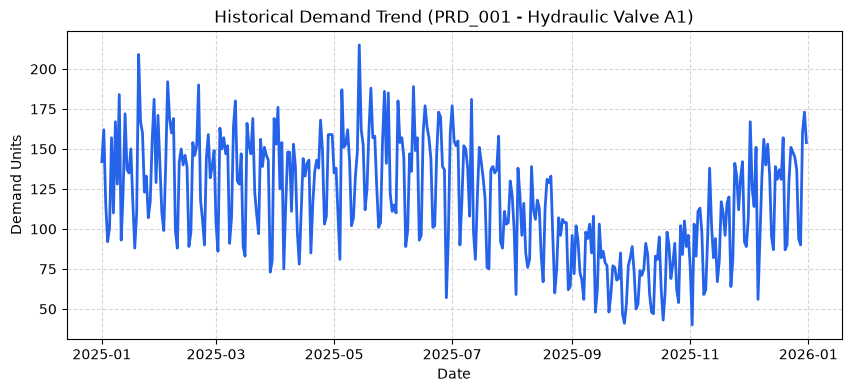

In [7]:
plt.figure(figsize=(10, 4))
sample_prod = df_clean[df_clean['Product_ID'] == 'PRD_001']
plt.plot(pd.to_datetime(sample_prod['Date']), sample_prod['Demand'], color='#2563EB', linewidth=2)
plt.title("Historical Demand Trend (PRD_001 - Hydraulic Valve A1)")
plt.xlabel("Date")
plt.ylabel("Demand Units")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Step 8: Feature Engineering

In [8]:
from src.feature_engineering import create_features

df_featured, feature_cols, target_col = create_features(df_clean)
print(f"Engineered Features ({len(feature_cols)}):", feature_cols)
print("Target Column:", target_col)
df_featured[feature_cols + [target_col]].head()

Engineered Features (11): ['Year', 'Month', 'Day', 'Day_of_Week', 'Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Rolling_Mean_30', 'Current_Stock', 'Lead_Time_Days', 'Previous_Sales']
Target Column: Demand


,Year,Month,Day,Day_of_Week,Lag_1,Lag_7,Rolling_Mean_7,Rolling_Mean_30,Current_Stock,Lead_Time_Days,Previous_Sales,Demand
0,2025,1,1,2,142.0,142.0,142.0,142.0,252,5,142.0,142
1,2025,1,2,3,142.0,162.0,142.0,142.0,558,5,142.0,162
2,2025,1,3,4,162.0,116.0,152.0,152.0,396,5,162.0,116
3,2025,1,4,5,116.0,92.0,140.0,140.0,280,5,116.0,92
4,2025,1,5,6,92.0,101.0,128.0,128.0,188,5,92.0,101


### Step 9: Define X (Features Matrix) and y (Target Vector)

In [9]:
X = df_featured[feature_cols]
y = df_featured[target_col]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3650, 11)
y shape: (3650,)


### Step 10: Chronological Train / Test Split (80% Train, 20% Test)

In [10]:
split_idx = int(len(df_featured) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
test_df = df_featured.iloc[split_idx:].copy()

print(f"Training samples (X_train): {len(X_train)}")
print(f"Testing samples (X_test)  : {len(X_test)}")

Training samples (X_train): 2920
Testing samples (X_test)  : 730


### Step 11: Instantiate Linear Regression Model

In [11]:
model = LinearRegression()
print("Linear Regression model instantiated:", model)

Linear Regression model instantiated: LinearRegression()


### Step 12: Actual Model Training (`model.fit(X_train, y_train)`)

In [12]:
# EXECUTING ACTUAL MODEL TRAINING LINE
model.fit(X_train, y_train)
print("Model training completed via model.fit(X_train, y_train)!")

Model training completed via model.fit(X_train, y_train)!


### Step 13: Generate Predictions on Test Set

In [13]:
y_pred = model.predict(X_test)
y_pred = np.maximum(0, y_pred) # Non-negative demand constraint
test_df['Predicted_Demand'] = np.round(y_pred, 2)
print("Generated predictions for test samples.")
test_df[['Date', 'Product_ID', 'Current_Stock', 'Lead_Time_Days', 'Demand', 'Predicted_Demand']].head()

Generated predictions for test samples.


,Date,Product_ID,Current_Stock,Lead_Time_Days,Demand,Predicted_Demand
2920,2025-01-01,PRD_009,229,3,261,228.74
2921,2025-01-02,PRD_009,1008,3,352,282.67
2922,2025-01-03,PRD_009,656,3,344,295.19
2923,2025-01-04,PRD_009,1214,3,172,188.46
2924,2025-01-05,PRD_009,1042,3,160,161.42


### Step 14 - 17: Calculate Evaluation Metrics (MAE, MSE, RMSE, R² Score)

In [14]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Step 14 - MAE     : {mae:.4f}")
print(f"Step 15 - MSE     : {mse:.4f}")
print(f"Step 16 - RMSE    : {rmse:.4f}")
print(f"Step 17 - R² Score: {r2:.4f} ({r2*100:.2f}% Variance Explained)")

Step 14 - MAE     : 21.1826
Step 15 - MSE     : 881.5660
Step 16 - RMSE    : 29.6912
Step 17 - R² Score: 0.9037 (90.37% Variance Explained)


### Step 18: Show Actual vs Predicted Demand Graph

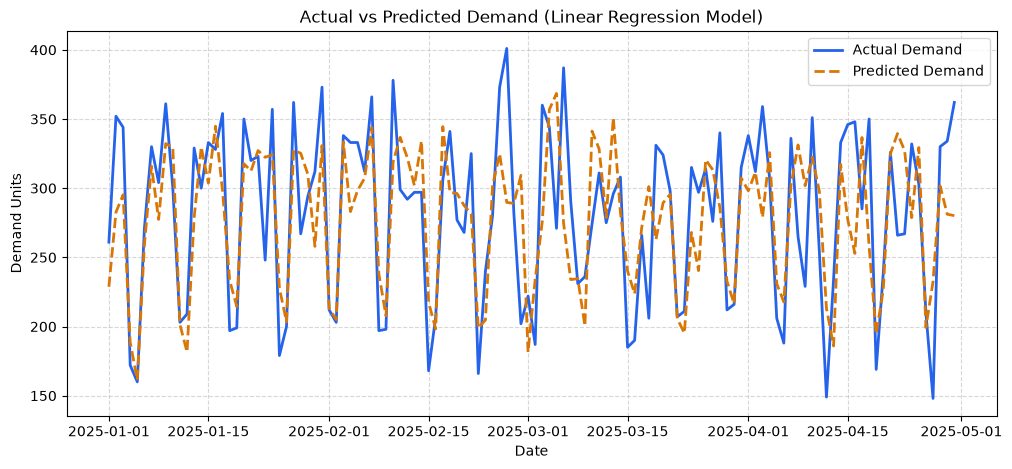

In [15]:
plt.figure(figsize=(12, 5))
plt.plot(pd.to_datetime(test_df['Date']).iloc[:120], y_test.iloc[:120], label='Actual Demand', color='#2563EB', linewidth=2)
plt.plot(pd.to_datetime(test_df['Date']).iloc[:120], y_pred[:120], label='Predicted Demand', color='#D97706', linestyle='--', linewidth=2)
plt.title("Actual vs Predicted Demand (Linear Regression Model)")
plt.xlabel("Date")
plt.ylabel("Demand Units")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Step 19: Save Trained Model

In [16]:
os.makedirs("../models", exist_ok=True)
model_path = "../models/linear_regression_model.pkl"

with open(model_path, "wb") as f:
    pickle.dump(model, f)

print(f"Saved trained model successfully to '{model_path}'.")

Saved trained model successfully to '../models/linear_regression_model.pkl'.


### Step 20: Demonstrate Loading the Saved Model

In [17]:
with open(model_path, "rb") as f:
    loaded_model = pickle.load(f)

print("Loaded model object successfully:", loaded_model)

Loaded model object successfully: LinearRegression()


### Step 21: Generate a Sample Prediction Using Loaded Model

In [18]:
sample_input = pd.DataFrame([{
    'Year': 2025, 'Month': 7, 'Day': 20, 'Day_of_Week': 6,
    'Lag_1': 140.0, 'Lag_7': 135.0, 'Rolling_Mean_7': 138.0, 'Rolling_Mean_30': 130.0,
    'Current_Stock': 180, 'Lead_Time_Days': 5, 'Previous_Sales': 140.0
}])

sample_pred = loaded_model.predict(sample_input)[0]
print(f"Sample ML Input Features: Year=2025, Month=7, Lag_1=140.0, Current_Stock=180")
print(f"Predicted Daily Demand  : {max(0, round(float(sample_pred), 2))} units")

Sample ML Input Features: Year=2025, Month=7, Lag_1=140.0, Current_Stock=180
Predicted Daily Demand  : 126.25 units
